# Segmentation crops
Candidate regions, zoom-ins, a row of selected methods and grids of all methods per region, saved to `metrics/merged/plots/segmentation_crops/<roi>/`.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import spatialdata as sd
from matplotlib import font_manager

sys.path.insert(0, str(Path.cwd().parents[0]))
from cellseg_benchmark import crop_plots as cp
from cellseg_benchmark._constants import BASE_PATH, method_names

font_manager.fontManager.addfont(f"{BASE_PATH}/misc/Arial.ttf")
plt.rcParams.update({"font.family": "Arial", "svg.fonttype": "none"})
rois = {"pial": ("aging_s5_r1", (645, 3845, 145))}  # sample, (xmin, ymin, size) in µm
row_methods = ["Baysor_2D_denovo", "vpt_2D_DAPI_PolyT", "vpt_3D_DAPI_PolyT", "Proseg_3D_vpt3D_DAPI_nuclei"]
out = Path(BASE_PATH) / "metrics/merged/plots/segmentation_crops"

/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


## Candidate regions
Listed candidates become 100 µm regions; paste the printed entry into `rois` to keep it.

In [2]:
candidates = cp.find_candidates("aging", exclude=["aging_s5_r1"])
for i in []:
    r = candidates.loc[i]
    rois[f"c{i}"] = (r["sample"], (r.x0, r.y0, 70))
    print(f'"c{i}": {rois[f"c{i}"]},')
sdatas = {s: sd.read_zarr(Path(BASE_PATH) / "samples" / s / "sdata_z3.zarr", selection=("images", "shapes"))
          for s in {s for s, _ in rois.values()} | set(candidates["sample"])}
candidates

version mismatch: detected: RasterFormatV02, requested: FormatV04


"c6": ('aging_s10_r0', (np.float64(13362.5), np.float64(1907.5), 100)),


/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserW

,sample,x0,y0,n,vsi,d
0,aging_s11_r0,11020.0,9570.0,81,0.702835,0.0
1,aging_s10_r0,7975.0,1740.0,81,0.715986,0.0
2,aging_s11_r1,11890.0,2320.0,81,0.720071,0.0
3,aging_s11_r1,9860.0,1015.0,81,0.738604,0.0
4,aging_s1_r1,2465.0,5220.0,81,0.749045,0.0
5,aging_s10_r2,12180.0,7105.0,81,0.750004,0.0
6,aging_s10_r0,13340.0,1885.0,81,0.755571,0.0
7,aging_s8_r0,1740.0,6235.0,81,0.758662,0.0


## Overview and zoom-ins

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


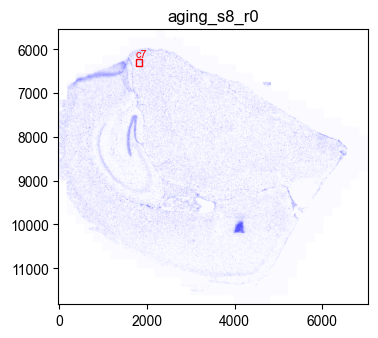

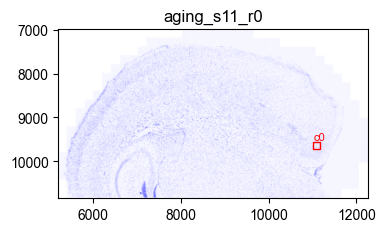

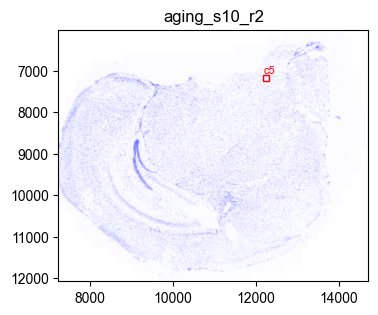

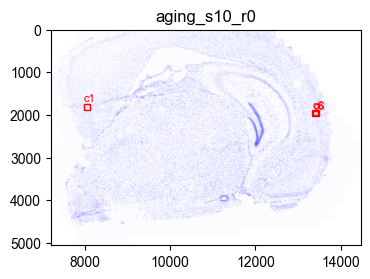

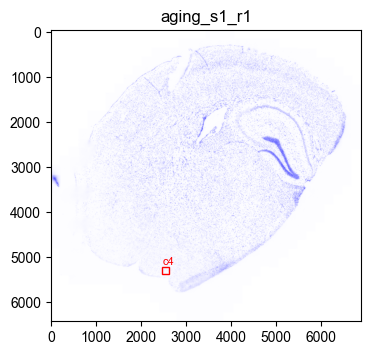

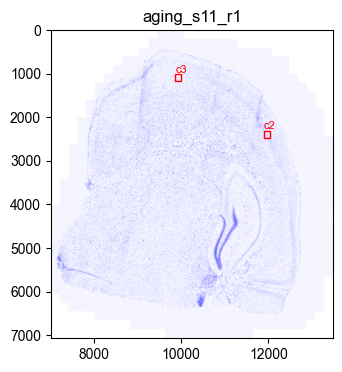

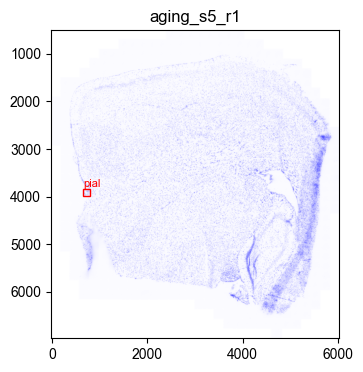

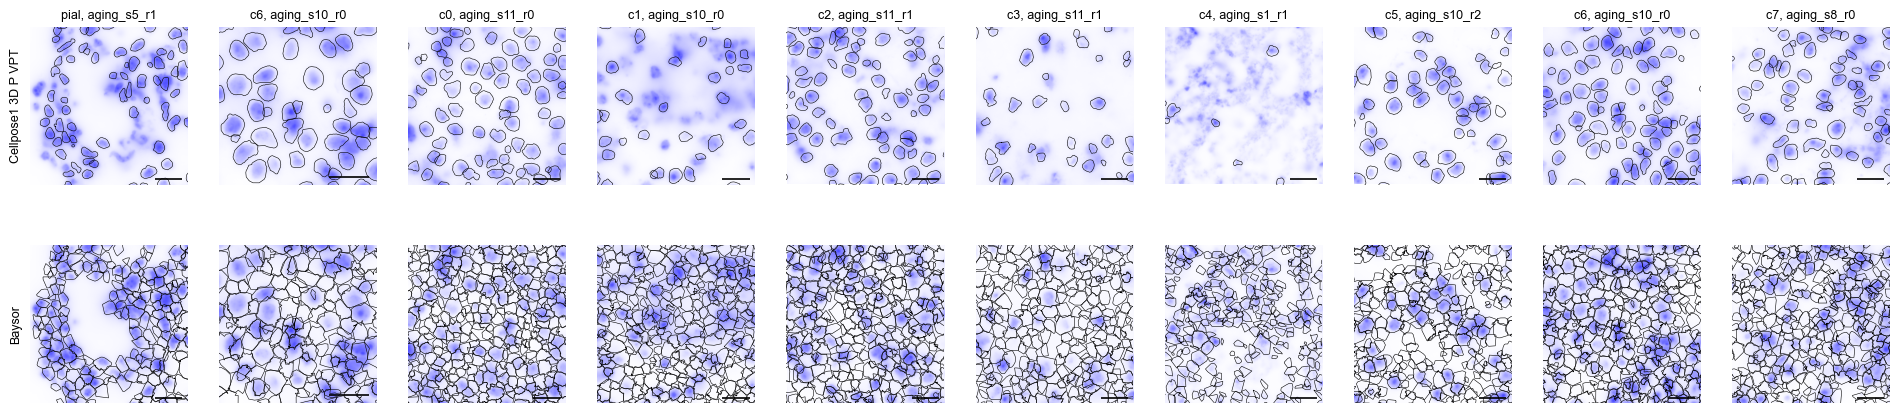

In [3]:
boxes = [(r, s, b) for r, (s, b) in rois.items()] + [(f"c{i}", r["sample"], (r.x0, r.y0, 70)) for i, r in candidates.iterrows()]
for s, sdata in sdatas.items():
    fig, ax = plt.subplots(figsize=(4, 4))
    sdata.pl.render_images(f"{s}_z3", channel="DAPI", cmap=cp.dapi_cmap, colorbar=False).pl.show(coordinate_systems="micron", ax=ax, title=s)
    for name, _, (x, y, size) in [b for b in boxes if b[1] == s]:
        ax.add_patch(plt.Rectangle((x, y), size, size, fill=False, ec="red", lw=1))
        ax.text(x, y, name, color="red", fontsize=8, va="bottom")

methods = ["vpt_3D_DAPI_PolyT", "Baysor_2D_denovo"]
fig, axs = plt.subplots(2, len(boxes), figsize=(2.4 * len(boxes), 5.2), squeeze=False)
for j, (name, s, b) in enumerate(boxes):
    for i, m in enumerate(methods):
        cp.draw(axs[i, j], sdatas[s], s, m, b)
    axs[0, j].set_title(f"{name}, {s}", fontsize=9)
for i, m in enumerate(methods):
    axs[i, 0].text(-0.05, 0.5, method_names[m], transform=axs[i, 0].transAxes, rotation=90, ha="right", va="center", fontsize=9)

## Method row
Preview one row, then save all.

/dss/dsshome1/0C/ra98gaq/git/cbm-celltype/cellseg_benchmark/crop_plots.py:87: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  g[~kept].boundary.plot(ax=ax, aspect=None, color="0.5", lw=lw)
/dss/dsshome1/0C/ra98gaq/git/cbm-celltype/cellseg_benchmark/crop_plots.py:87: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  g[~kept].boundary.plot(ax=ax, aspect=None, color="0.5", lw=lw)


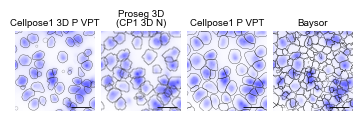

In [4]:
s, b = rois["c6"]
cp.plot_row(sdatas[s], s, row_methods, b, "outlines", "both");

In [5]:
for roi, (s, b) in rois.items():
    (out / roi).mkdir(parents=True, exist_ok=True)
    for style in ("outlines", "transcripts"):
        for qc in ("post", "both"):
            fig = cp.plot_row(sdatas[s], s, row_methods, b, style, qc)
            fig.savefig(out / roi / f"row_{style}_{qc}qc.png", dpi=600, bbox_inches="tight", pad_inches=0.02, transparent=True)  # add .svg for the final export
            plt.close(fig)

/dss/dsshome1/0C/ra98gaq/git/cbm-celltype/cellseg_benchmark/crop_plots.py:87: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  g[~kept].boundary.plot(ax=ax, aspect=None, color="0.5", lw=lw)
/dss/dsshome1/0C/ra98gaq/git/cbm-celltype/cellseg_benchmark/crop_plots.py:87: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  g[~kept].boundary.plot(ax=ax, aspect=None, color="0.5", lw=lw)
/dss/dsshome1/0C/ra98gaq/git/cbm-celltype/cellseg_benchmark/crop_plots.py:87: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  g[~kept].boundary.plot(ax=ax, aspect=None, color="0.5", lw=lw)
/dss/dsshome1/0C/ra98gaq/git/cbm-celltype/cellseg_benchmark/crop_plots.py:87: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  g[~kept].boundary.plot(ax=ax, aspect=None, color="0.5", lw=lw)


## Grids of all methods (slow)

In [6]:
for roi, (s, b) in rois.items():
    for style in ("outlines", "celltypes", "transcripts"):
        fig = cp.plot_grid(sdatas[s], s, b, style)
        fig.savefig(out / roi / f"grid_{style}.png", dpi=300, bbox_inches="tight")
        plt.close(fig)

/dss/dsshome1/0C/ra98gaq/git/cbm-celltype/cellseg_benchmark/crop_plots.py:82: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  order = np.argsort(-g.area.to_numpy())
/dss/dsshome1/0C/ra98gaq/git/cbm-celltype/cellseg_benchmark/crop_plots.py:82: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  order = np.argsort(-g.area.to_numpy())
